# Retail Sales Data: Exploratory Data Analysis

**Prepared by:** Saurabh Shukla

**Email:** saurabhshuklant@gmail.com

**Track:** Data Analytics | Level 1 | Task 1

**Tools:** Python, pandas, matplotlib, seaborn, Jupyter Notebook

## Introduction

Every retail business sits on a pile of transaction records, but a pile of rows doesn't tell anyone what to do next. The goal of this project is to open that pile up and see what it is actually saying: **when** customers buy, **who** they are, **what** they buy, and **where** the money really comes from.

I am working with a retail sales dataset of 1,000 transactions covering one year of sales (2023). Each row is one purchase and carries the customer's gender and age, the product category, the quantity bought, the price per unit and the total amount paid.

**Questions I want to answer**

1. Is the data clean and trustworthy enough to analyse?
2. How are sales distributed, and are there months or quarters that are clearly stronger or weaker?
3. Who are the customers (age and gender), and do different groups spend differently?
4. Which products and categories bring in the most units and the most revenue?
5. Which variables move together, and is there anything in the data that is not obvious at first glance?
6. What should the business actually *do* with all of this?

**About the dataset**

| Column | Description |
|---|---|
| Transaction ID | Unique ID of each sale |
| Date | Date of the transaction |
| Customer ID | Unique ID of the customer |
| Gender | Male / Female |
| Age | Age of the customer |
| Product Category | Beauty, Clothing or Electronics |
| Quantity | Number of units bought in the transaction |
| Price per Unit | Price of one unit |
| Total Amount | Quantity x Price per Unit (revenue of the transaction) |

*The dataset does not mention a currency, so all amounts are shown as plain numbers.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 13
pd.set_option('display.max_columns', None)

# one colour per category so every chart tells the same visual story
CAT_COLORS = {'Beauty': '#e377c2', 'Clothing': '#4c72b0', 'Electronics': '#dd8452'}
print('Libraries loaded.')

Libraries loaded.


## 1. Loading the Data and Initial Inspection

First step is always the same: load the file and check what we are dealing with. Shape, data types and missing values come before any analysis, because a surprise here can quietly ruin everything that follows.

In [2]:
df = pd.read_csv('retail_sales_dataset.csv')
print('Shape of the dataset (rows, columns):', df.shape)
df.head()

Shape of the dataset (rows, columns): (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [4]:
print('Null values per column:')
print(df.isnull().sum())
print()
print('Duplicate rows            :', df.duplicated().sum())
print('Duplicate Transaction IDs :', df['Transaction ID'].duplicated().sum())
print('Unique customers          :', df['Customer ID'].nunique())
print('Unique categories         :', df['Product Category'].unique().tolist())
print()
mismatch = (df['Total Amount'] != df['Quantity'] * df['Price per Unit']).sum()
print('Rows where Total Amount != Quantity x Price per Unit:', mismatch)

Null values per column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows            : 0
Duplicate Transaction IDs : 0
Unique customers          : 1000
Unique categories         : ['Beauty', 'Clothing', 'Electronics']

Rows where Total Amount != Quantity x Price per Unit: 0


**Observations**

- The dataset has **1,000 rows and 9 columns**, and there are **no missing values** in any column.
- There are **no duplicate rows** and no repeated Transaction IDs.
- Every one of the 1,000 transactions belongs to a **different customer** (1,000 unique Customer IDs). This is important: it means we cannot study repeat purchases or customer loyalty with this data, only single-purchase behaviour.
- `Total Amount` always equals `Quantity x Price per Unit`, so the revenue column is internally consistent and can be trusted.
- `Date` is stored as plain text and `Age` and the amounts are integers. The date column needs to be converted to a proper datetime before we can do any time-based analysis.
- Because the data is already clean, no rows had to be dropped or imputed.

### Preparing the data

A few helper columns will make the later analysis much easier: month, quarter, day of week, an age-group bucket, and a "Product" label. The dataset has no product names, only a category and a price per unit, so I combine the two (for example *Clothing | 500*) to get a product-level view later on.

In [5]:
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.to_period('M')
df['Quarter'] = df['Date'].dt.to_period('Q')
df['Day of Week'] = df['Date'].dt.day_name()
df['Age Group'] = pd.cut(df['Age'], bins=[17, 25, 35, 45, 55, 65],
                         labels=['18-25', '26-35', '36-45', '46-55', '56-65'])
df['Product'] = df['Product Category'] + ' | ' + df['Price per Unit'].astype(str)

print('Date range:', df['Date'].min().date(), 'to', df['Date'].max().date())
print()
print('Transactions per year:')
print(df['Date'].dt.year.value_counts().sort_index())
print()
print('--- Quick business snapshot ---')
print('Total revenue          :', f"{df['Total Amount'].sum():,}")
print('Total transactions     :', f"{len(df):,}")
print('Total units sold       :', f"{df['Quantity'].sum():,}")
print('Average order value    :', round(df['Total Amount'].mean(), 2))
print('Median order value     :', df['Total Amount'].median())

Date range: 2023-01-01 to 2024-01-01

Transactions per year:
Date
2023    998
2024      2
Name: count, dtype: int64

--- Quick business snapshot ---
Total revenue          : 456,000
Total transactions     : 1,000
Total units sold       : 2,514
Average order value    : 456.0
Median order value     : 135.0


**Observations**

- The data runs from **1 January 2023 to 1 January 2024**. Only **2 transactions** fall in 2024 (both on the very first day), so 2024 is effectively an incomplete month.
- To keep the trend analysis fair, I will use **only 2023 (998 transactions)** for the monthly and quarterly charts. Everywhere else the full dataset is used.
- In total the business made **456,000 in revenue** from **1,000 orders** and **2,514 units**, which is an average order value of **456**. The median order is only **135**, which is a big gap that we will dig into in the next section.

## 2. Descriptive Statistics

Mean, median, mode and standard deviation for every numerical column. `Transaction ID` is left out because it is just a label, not a measurement.

In [6]:
num_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

stats = pd.DataFrame({
    'Mean': df[num_cols].mean(),
    'Median': df[num_cols].median(),
    'Mode': df[num_cols].mode().iloc[0],
    'Std Dev': df[num_cols].std(),
    'Min': df[num_cols].min(),
    'Max': df[num_cols].max(),
    'Skewness': df[num_cols].skew()
}).round(2)
stats

,Mean,Median,Mode,Std Dev,Min,Max,Skewness
Age,41.39,42.0,43.0,13.68,18,64,-0.05
Quantity,2.51,3.0,4.0,1.13,1,4,-0.01
Price per Unit,179.89,50.0,50.0,189.68,25,500,0.74
Total Amount,456.00,135.0,50.0,560.00,25,2000,1.38


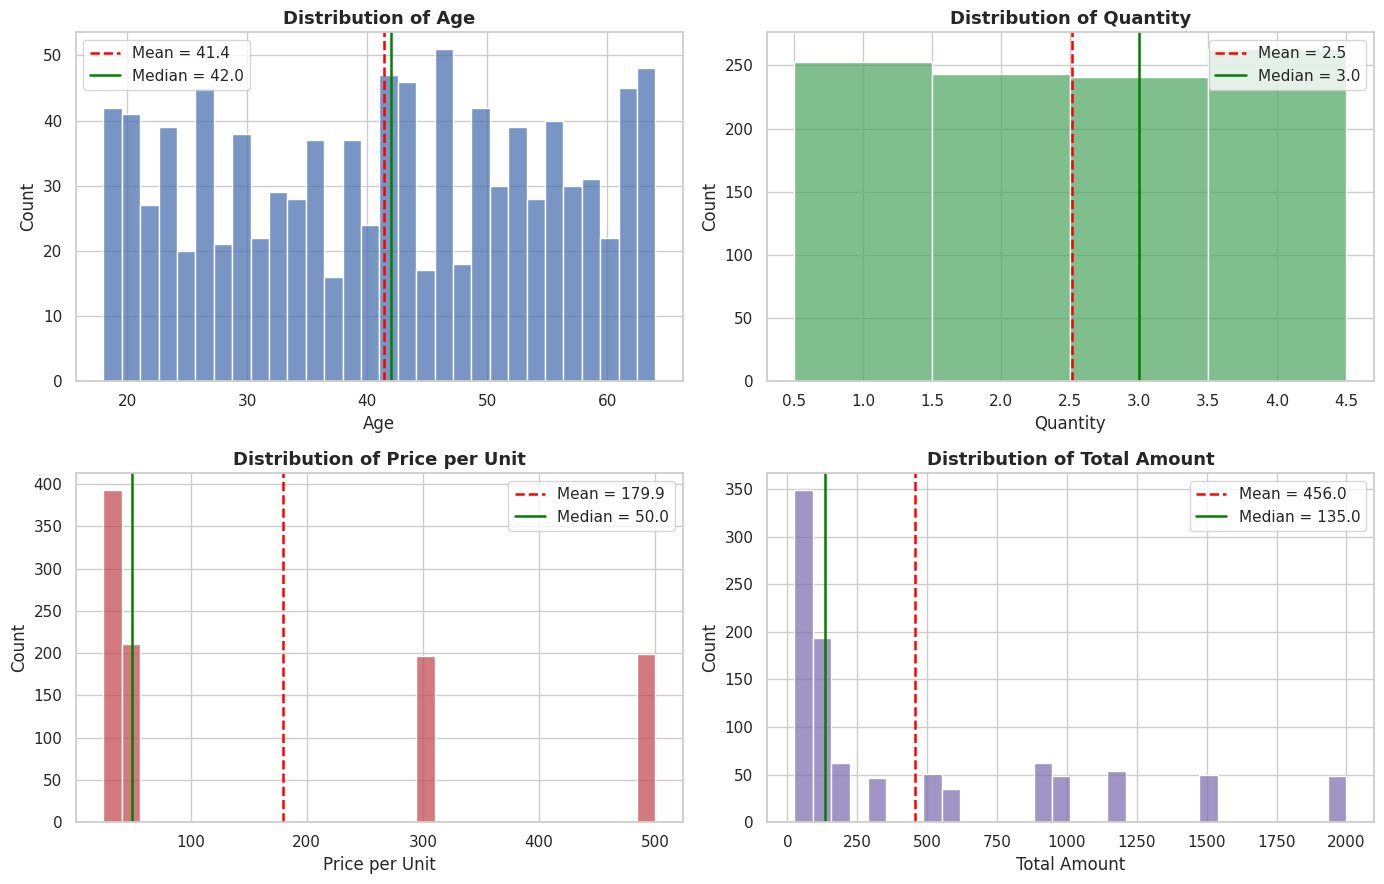

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
colors = ['#4c72b0', '#55a868', '#c44e52', '#8172b2']

for ax, col, c in zip(axes.ravel(), num_cols, colors):
    sns.histplot(df[col], ax=ax, color=c, bins=30 if col != 'Quantity' else 4,
                 discrete=(col == 'Quantity'), edgecolor='white')
    ax.axvline(df[col].mean(), color='red', ls='--', lw=1.8, label=f'Mean = {df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='green', ls='-', lw=1.8, label=f'Median = {df[col].median():.1f}')
    ax.set_title(f'Distribution of {col}')
    ax.legend()

plt.tight_layout()
plt.show()

**Observations**

- **Age** is almost perfectly symmetrical (mean 41.4, median 42, skewness close to 0). Customers range from 18 to 64, so the shop serves a wide adult audience rather than one narrow age band.
- **Quantity** is spread evenly across 1, 2, 3 and 4 units, with an average of about 2.5. Nobody in this data buys more than 4 units in one go.
- **Price per Unit** only takes five values (25, 30, 50, 300, 500). So this is really a business with a *cheap tier* (25 to 50) and a *premium tier* (300 and 500), with nothing in between.
- **Total Amount** is strongly right-skewed (skewness about 1.4). The **mean (456) is more than three times the median (135)**, which tells us a small number of high-value orders are pulling the average up. The "typical" order is much smaller than the average suggests, and the standard deviation (about 560) is larger than the mean itself.

## 3. Time Series Analysis: Monthly and Quarterly Sales Trends

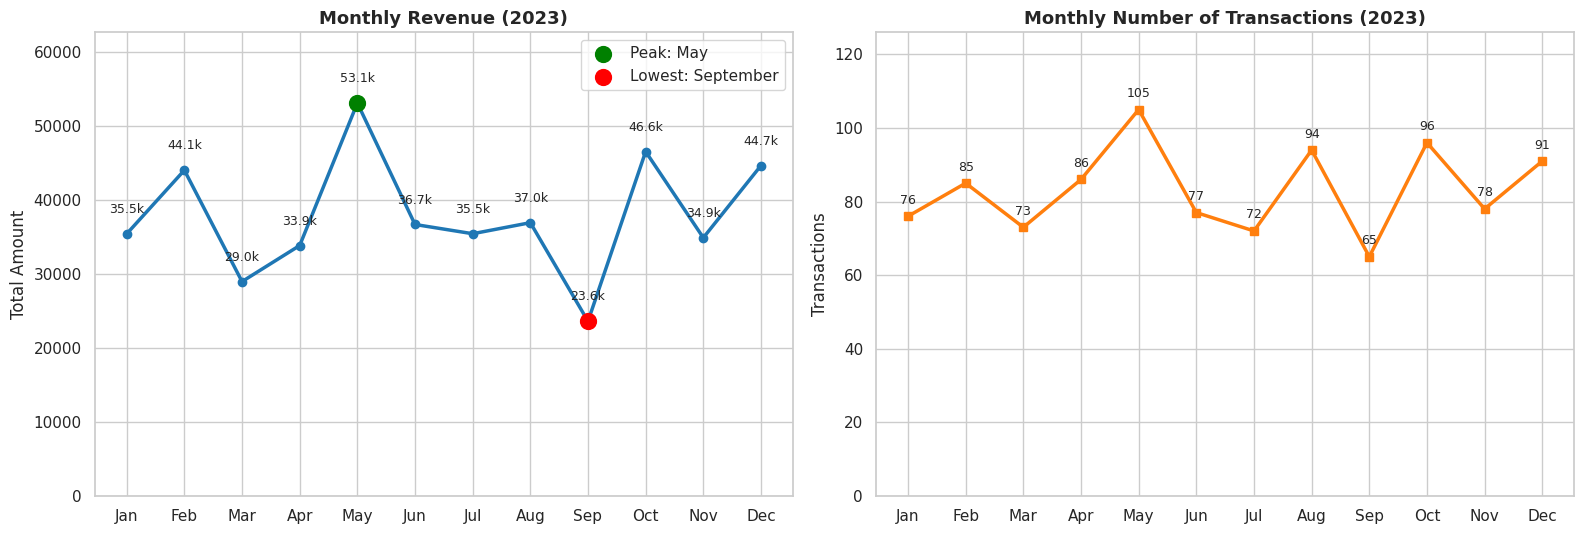

In [8]:
df23 = df[df['Date'] < '2024-01-01'].copy()

monthly_rev = df23.groupby('Month')['Total Amount'].sum()
monthly_txn = df23.groupby('Month')['Transaction ID'].count()
months = monthly_rev.index.strftime('%b')

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# revenue
axes[0].plot(months, monthly_rev.values, marker='o', lw=2.5, color='#1f77b4')
for i, v in enumerate(monthly_rev.values):
    axes[0].annotate(f'{v/1000:.1f}k', (i, v), textcoords='offset points', xytext=(0, 15), ha='center', fontsize=9)
peak, low = monthly_rev.idxmax(), monthly_rev.idxmin()
axes[0].scatter([peak.strftime('%b')], [monthly_rev.max()], color='green', s=130, zorder=5, label=f'Peak: {peak.strftime("%B")}')
axes[0].scatter([low.strftime('%b')], [monthly_rev.min()], color='red', s=130, zorder=5, label=f'Lowest: {low.strftime("%B")}')
axes[0].set_title('Monthly Revenue (2023)')
axes[0].set_ylabel('Total Amount')
axes[0].set_ylim(0, monthly_rev.max() * 1.18)
axes[0].legend()

# transactions
axes[1].plot(months, monthly_txn.values, marker='s', lw=2.5, color='#ff7f0e')
for i, v in enumerate(monthly_txn.values):
    axes[1].annotate(str(v), (i, v), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=9)
axes[1].set_title('Monthly Number of Transactions (2023)')
axes[1].set_ylabel('Transactions')
axes[1].set_ylim(0, monthly_txn.max() * 1.2)

plt.tight_layout()
plt.show()

**Observations**

- Sales are **not flat through the year**; they swing a lot from month to month.
- **May is the best month** with 53,150 in revenue and also the most orders (105). **September is the weakest** with only 23,620 and 65 orders, less than half of May.
- **October jumps back by about 97%** over September (23,620 to 46,580), which is the sharpest rebound of the year. February and December are also strong (44,060 and 44,690).
- Revenue and order count move together in most months, but not always. August had 94 orders yet only 36,960 in revenue, meaning customers bought cheaper items that month (one of the lowest average order values of the year, around 393).

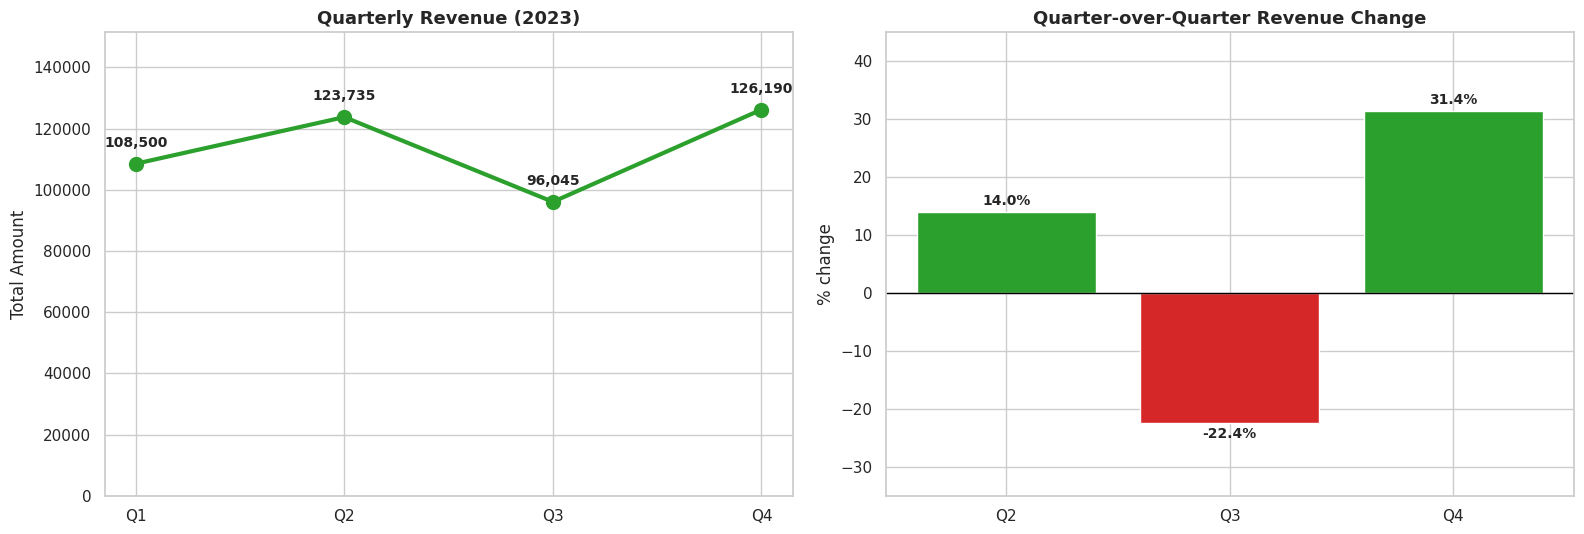

         Revenue
Quarter         
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190


In [9]:
quarterly = df23.groupby('Quarter')['Total Amount'].sum()
q_labels = ['Q1', 'Q2', 'Q3', 'Q4']
qoq = quarterly.pct_change() * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].plot(q_labels, quarterly.values, marker='o', lw=3, color='#2ca02c', markersize=10)
for i, v in enumerate(quarterly.values):
    axes[0].annotate(f'{v:,}', (i, v), textcoords='offset points', xytext=(0, 12), ha='center', fontsize=10, fontweight='bold')
axes[0].set_title('Quarterly Revenue (2023)')
axes[0].set_ylabel('Total Amount')
axes[0].set_ylim(0, quarterly.max() * 1.2)

bar_colors = ['#2ca02c' if x >= 0 else '#d62728' for x in qoq.values[1:]]
bars = axes[1].bar(q_labels[1:], qoq.values[1:], color=bar_colors)
axes[1].bar_label(bars, fmt='%.1f%%', padding=3, fontsize=10, fontweight='bold')
axes[1].axhline(0, color='black', lw=1)
axes[1].set_title('Quarter-over-Quarter Revenue Change')
axes[1].set_ylabel('% change')
axes[1].set_ylim(-35, 45)

plt.tight_layout()
plt.show()

print(quarterly.rename(index=lambda q: str(q)).to_frame('Revenue'))

**Observations**

- **Q4 is the strongest quarter** (126,190), followed closely by Q2 (123,735). **Q3 is clearly the weakest** (96,045).
- Q2 grew about **14% over Q1**, then Q3 **fell about 22%**, and Q4 **bounced back by about 31%**.
- The Q3 dip is driven mostly by **September**, the worst month of the year. Whatever causes the late-summer slowdown, the business recovers quickly once October arrives, which hints at a seasonal or festive-season effect.
- Overall, the business is healthy, with no long-term decline, but it has a very visible mid-year weakness.

## 4. Customer Demographics: Age and Gender

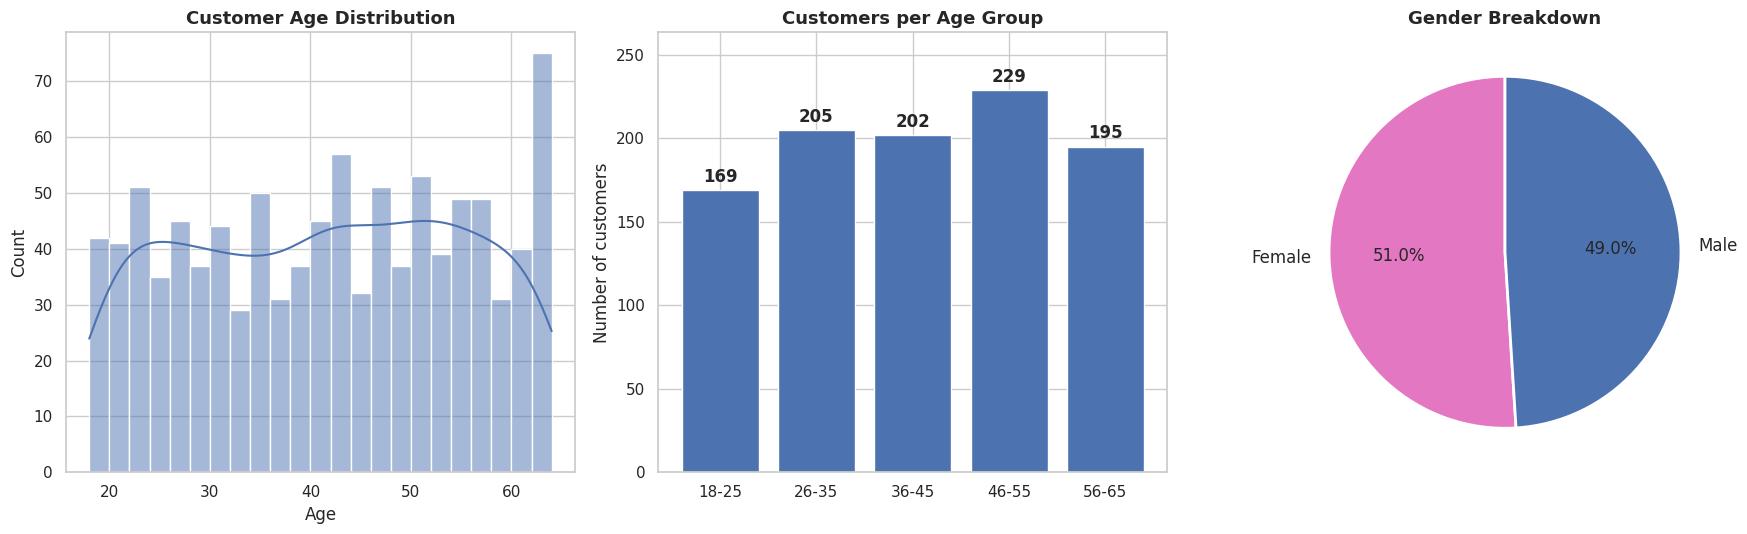

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# age distribution
sns.histplot(df['Age'], bins=23, kde=True, ax=axes[0], color='#4c72b0', edgecolor='white')
axes[0].set_title('Customer Age Distribution')

# age groups
age_counts = df['Age Group'].value_counts().sort_index()
bars = axes[1].bar(age_counts.index.astype(str), age_counts.values, color='#4c72b0')
axes[1].bar_label(bars, padding=3, fontweight='bold')
axes[1].set_title('Customers per Age Group')
axes[1].set_ylabel('Number of customers')
axes[1].set_ylim(0, age_counts.max() * 1.15)

# gender
g = df['Gender'].value_counts()
axes[2].pie(g.values, labels=g.index, autopct='%1.1f%%', startangle=90,
            colors=['#e377c2', '#4c72b0'], wedgeprops={'edgecolor': 'white', 'linewidth': 2},
            textprops={'fontsize': 12})
axes[2].set_title('Gender Breakdown')

plt.tight_layout()
plt.show()

**Observations**

- Customers are spread fairly evenly across adult age groups. The **46-55 group is the largest (229 customers)**, followed by 26-35 (205) and 36-45 (202). The 18-25 group is the smallest (169), partly because it covers fewer years (18 to 25) than the other buckets.
- The gender split is almost perfectly balanced: **51% female (510) and 49% male (490)**. The business is not dependent on one gender.

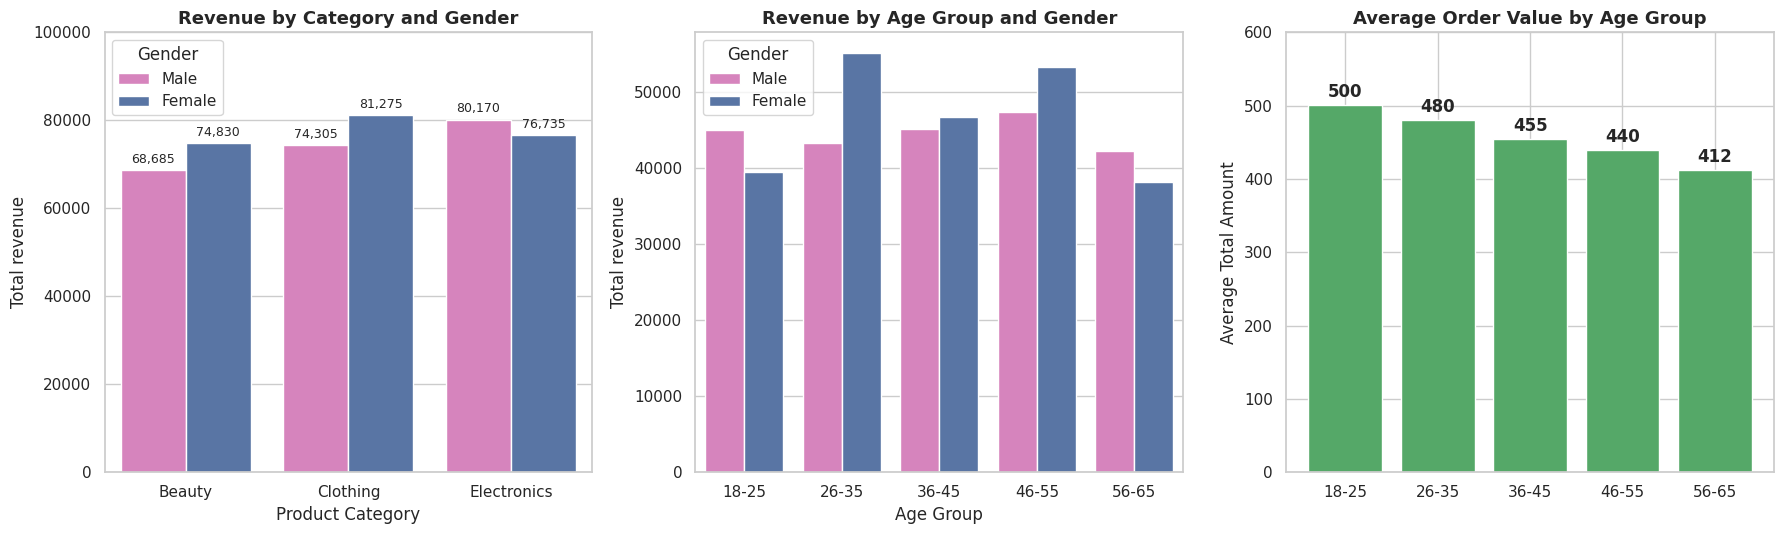

Average order value by gender:
Gender
Female    456.5
Male      455.4
Name: Total Amount, dtype: float64


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. spend by gender and category
sns.barplot(data=df, x='Product Category', y='Total Amount', hue='Gender', estimator=sum,
            errorbar=None, palette=['#e377c2', '#4c72b0'], ax=axes[0])
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='{:,.0f}', padding=3, fontsize=9)
axes[0].set_title('Revenue by Category and Gender')
axes[0].set_ylabel('Total revenue')
axes[0].set_ylim(0, 100000)

# 2. revenue by age group and gender
sns.barplot(data=df, x='Age Group', y='Total Amount', hue='Gender', estimator=sum,
            errorbar=None, palette=['#e377c2', '#4c72b0'], ax=axes[1])
axes[1].set_title('Revenue by Age Group and Gender')
axes[1].set_ylabel('Total revenue')

# 3. average order value by age group
aov = df.groupby('Age Group', observed=True)['Total Amount'].mean()
bars = axes[2].bar(aov.index.astype(str), aov.values, color='#55a868')
axes[2].bar_label(bars, fmt='%.0f', padding=3, fontweight='bold')
axes[2].set_title('Average Order Value by Age Group')
axes[2].set_ylabel('Average Total Amount')
axes[2].set_ylim(0, 600)

plt.tight_layout()
plt.show()

print('Average order value by gender:')
print(df.groupby('Gender')['Total Amount'].mean().round(1))

**Observations**

- **Women contribute slightly more revenue** (232,840 vs 223,160), but this is just because there are a few more female customers. **The average order value is virtually identical** (about 456.5 for women and 455.4 for men), so neither gender spends more per purchase.
- What *does* differ is **what they buy**. Women spend the most on **Clothing** (81,275), while men spend the most on **Electronics** (80,170). Beauty is the weakest category for both, but women spend a bit more on it (74,830 vs 68,685).
- The standout group is **women aged 26-35**, with 55,115 in revenue, roughly 12,000 more than men in the same age band (43,365). Women aged 46-55 are also strong (53,310).
- **Average order value falls steadily with age**: 18-25 customers spend about **500 per order**, while 56-65 customers spend about **412**. Younger customers are fewer in number but each one spends more.

## 5. Product Analysis

**A note on "top 10 products":** this dataset has no product names or SKUs, only a *category* and a *price per unit*. The closest thing to a "product" is therefore a **category + price point** combination (for example *Clothing | 300*). That gives 15 distinct products (3 categories x 5 price points), and I rank those.

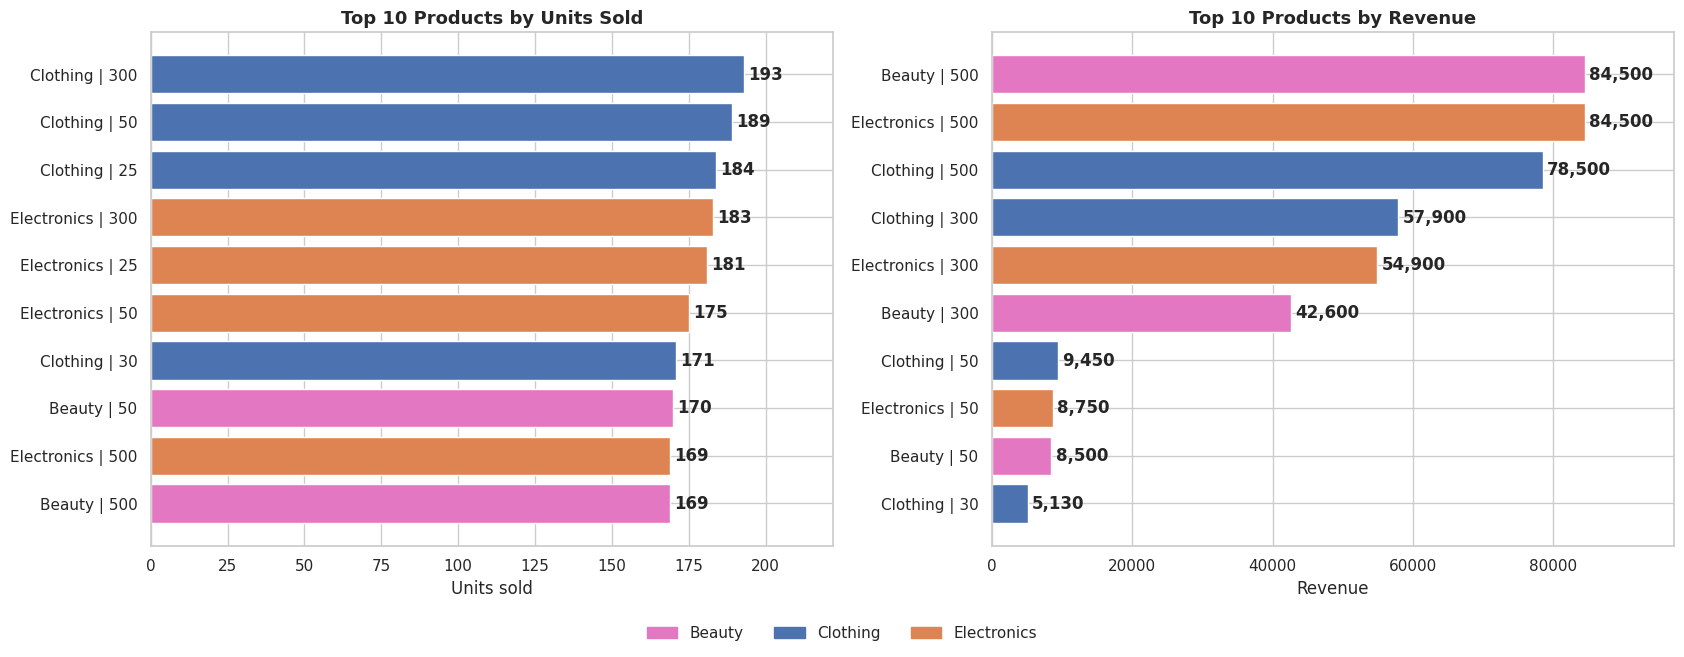

In [12]:
product_summary = df.groupby('Product').agg(
    Units_Sold=('Quantity', 'sum'),
    Revenue=('Total Amount', 'sum'),
    Transactions=('Transaction ID', 'count')
).reset_index()

top_units = product_summary.sort_values('Units_Sold', ascending=False).head(10)
top_rev = product_summary.sort_values('Revenue', ascending=False).head(10)

def cat_color(p):
    return CAT_COLORS[p.split(' | ')[0]]

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

b1 = axes[0].barh(top_units['Product'][::-1], top_units['Units_Sold'][::-1],
                  color=[cat_color(p) for p in top_units['Product'][::-1]])
axes[0].bar_label(b1, padding=3, fontweight='bold')
axes[0].set_title('Top 10 Products by Units Sold')
axes[0].set_xlabel('Units sold')
axes[0].set_xlim(0, top_units['Units_Sold'].max() * 1.15)

b2 = axes[1].barh(top_rev['Product'][::-1], top_rev['Revenue'][::-1],
                  color=[cat_color(p) for p in top_rev['Product'][::-1]])
axes[1].bar_label(b2, fmt='{:,.0f}', padding=3, fontweight='bold')
axes[1].set_title('Top 10 Products by Revenue')
axes[1].set_xlabel('Revenue')
axes[1].set_xlim(0, top_rev['Revenue'].max() * 1.15)

from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=c, label=k) for k, c in CAT_COLORS.items()],
           loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

**Observations**

- The two rankings tell **completely different stories**.
- By **units sold**, the cheap items dominate: six of the top ten are priced at 50 or below. The top seller is *Clothing | 300* (193 units), then *Clothing | 50* (189) and *Clothing | 25* (184). People simply buy a lot of low-priced items.
- By **revenue**, the top six are **all premium products (price 300 or 500)**. *Electronics | 500* and *Beauty | 500* both bring in 84,500 and *Clothing | 500* follows with 78,500. A cheap product only appears from seventh place onward, with revenue below 10,000.
- *Clothing | 300* is the one product that does well on both lists (top seller by units and fourth by revenue), which makes it the most reliable performer in the range.

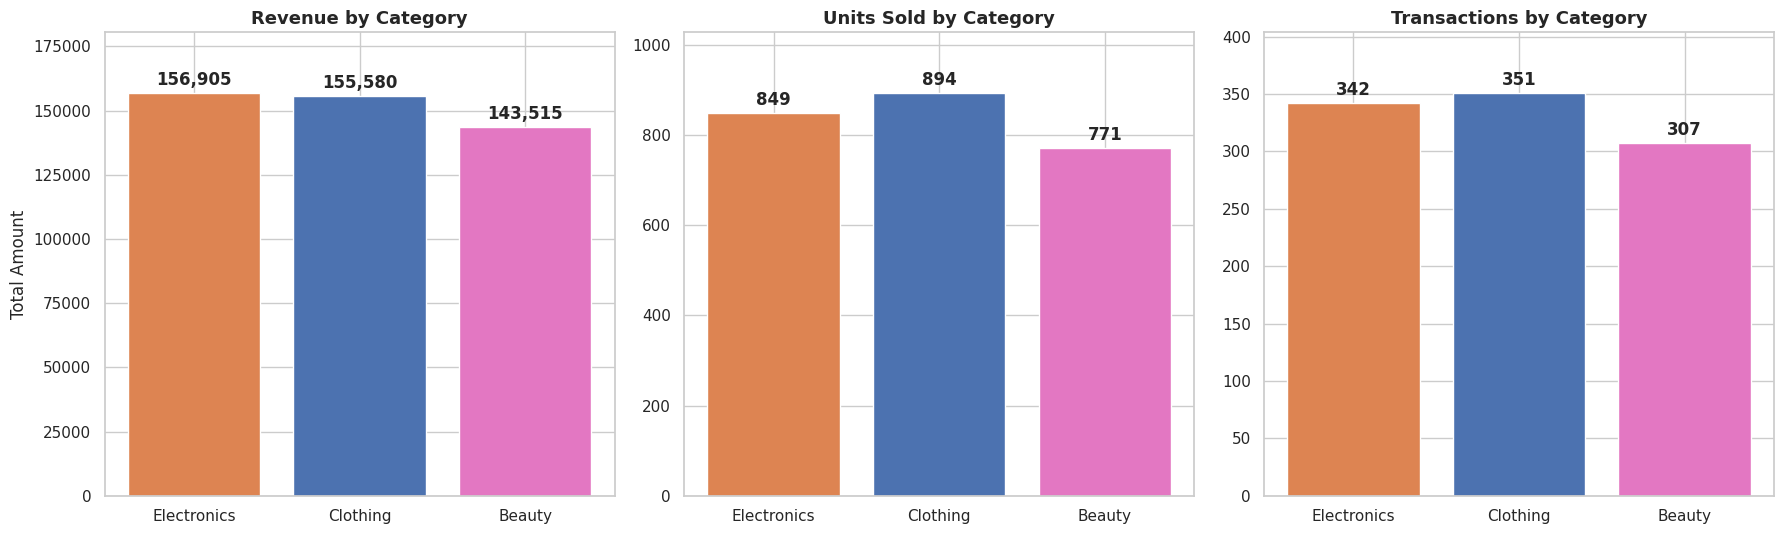

,Revenue,Units,Transactions,Revenue Share %
Product Category,,,,
Electronics,156905,849,342,34.4
Clothing,155580,894,351,34.1
Beauty,143515,771,307,31.5


In [13]:
cat_summary = df.groupby('Product Category').agg(
    Revenue=('Total Amount', 'sum'),
    Units=('Quantity', 'sum'),
    Transactions=('Transaction ID', 'count')
).reindex(['Electronics', 'Clothing', 'Beauty'])
cat_summary['Revenue Share %'] = (cat_summary['Revenue'] / cat_summary['Revenue'].sum() * 100).round(1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, col, title in zip(axes, ['Revenue', 'Units', 'Transactions'],
                          ['Revenue by Category', 'Units Sold by Category', 'Transactions by Category']):
    bars = ax.bar(cat_summary.index, cat_summary[col], color=[CAT_COLORS[c] for c in cat_summary.index])
    ax.bar_label(bars, fmt='{:,.0f}', padding=3, fontweight='bold')
    ax.set_title(title)
    ax.set_ylim(0, cat_summary[col].max() * 1.15)
axes[0].set_ylabel('Total Amount')

plt.tight_layout()
plt.show()

cat_summary

**Observations**

- The three categories are **very close in size**: Electronics 156,905 (34.4%), Clothing 155,580 (34.1%) and Beauty 143,515 (31.5%). No single category carries the business.
- **Electronics earns the most revenue despite having fewer transactions than Clothing** (342 vs 351), which means its orders are a bit more valuable.
- **Clothing sells the most units (894) and has the most transactions (351)**, so it is the category with the highest footfall.
- **Beauty is the weakest on every measure** (lowest revenue, units and transactions), but the gap to the other two is only about 8%, so it is a growth opportunity rather than a problem.

## 6. Correlation Heatmap

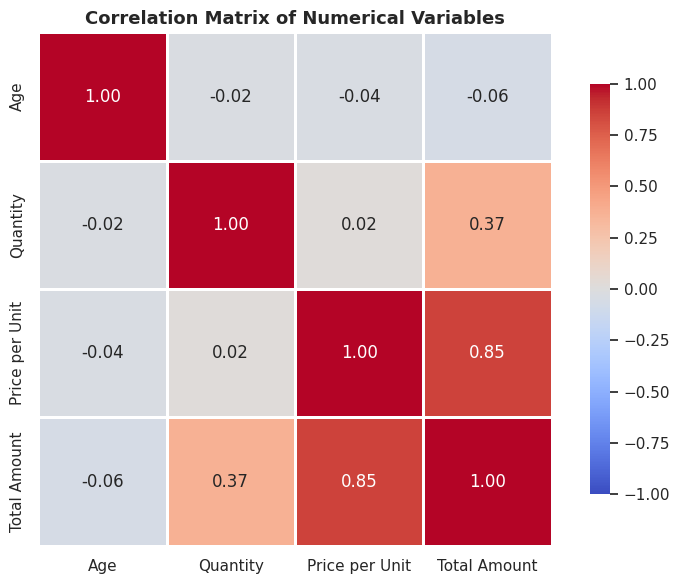

In [14]:
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=1, linecolor='white', square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

**Observations**

- **Price per Unit and Total Amount have a very strong positive correlation (0.85).** The price of the item is the main driver of how big an order is.
- **Quantity and Total Amount have a moderate positive correlation (0.37).** Buying more units raises the bill, but much less than buying a more expensive item does.
- **Quantity and Price per Unit are essentially uncorrelated (0.02).** Customers do not buy fewer units just because the item is expensive. This turns out to be important in the next section.
- **Age has almost no relationship with anything** (all values within about 0.06 of zero). Age alone is a weak predictor of how much someone spends, so age-based targeting should be combined with category and price information.

## 7. Additional Visualisations: Digging for Non-Obvious Insights

### 7.1 Where does the revenue really come from? (price-tier analysis)

From the earlier sections I noticed that price per unit drives revenue, but quantity does not depend on price. That made me curious: how much of the total revenue comes from the cheap items compared with the expensive ones?

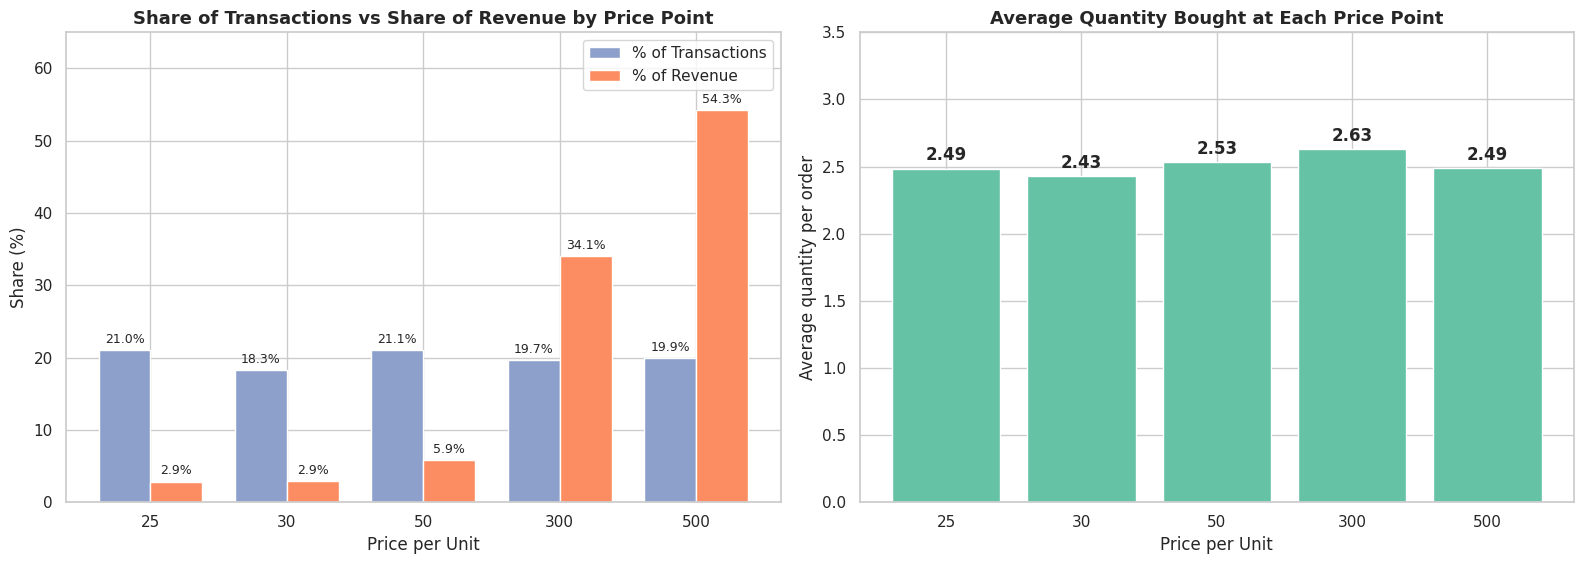

Premium orders (price 300 or 500): 396 orders = 39.6% of all orders
Revenue from premium orders: 402,900 = 88.4% of total revenue


In [15]:
tier = df.groupby('Price per Unit').agg(Transactions=('Transaction ID', 'count'),
                                        Revenue=('Total Amount', 'sum'),
                                        Avg_Qty=('Quantity', 'mean')).reset_index()
tier['% of Transactions'] = tier['Transactions'] / tier['Transactions'].sum() * 100
tier['% of Revenue'] = tier['Revenue'] / tier['Revenue'].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))

x = np.arange(len(tier))
w = 0.38
b1 = axes[0].bar(x - w/2, tier['% of Transactions'], w, label='% of Transactions', color='#8da0cb')
b2 = axes[0].bar(x + w/2, tier['% of Revenue'], w, label='% of Revenue', color='#fc8d62')
axes[0].bar_label(b1, fmt='%.1f%%', padding=3, fontsize=9)
axes[0].bar_label(b2, fmt='%.1f%%', padding=3, fontsize=9)
axes[0].set_xticks(x)
axes[0].set_xticklabels(tier['Price per Unit'])
axes[0].set_xlabel('Price per Unit')
axes[0].set_ylabel('Share (%)')
axes[0].set_title('Share of Transactions vs Share of Revenue by Price Point')
axes[0].set_ylim(0, 65)
axes[0].legend()

b3 = axes[1].bar(tier['Price per Unit'].astype(str), tier['Avg_Qty'], color='#66c2a5')
axes[1].bar_label(b3, fmt='%.2f', padding=3, fontweight='bold')
axes[1].set_xlabel('Price per Unit')
axes[1].set_ylabel('Average quantity per order')
axes[1].set_title('Average Quantity Bought at Each Price Point')
axes[1].set_ylim(0, 3.5)

plt.tight_layout()
plt.show()

premium = df[df['Price per Unit'] >= 300]
print(f"Premium orders (price 300 or 500): {len(premium)} orders = {len(premium)/len(df)*100:.1f}% of all orders")
print(f"Revenue from premium orders: {premium['Total Amount'].sum():,} = {premium['Total Amount'].sum()/df['Total Amount'].sum()*100:.1f}% of total revenue")

**Observations: this is the most important finding of the analysis**

- Orders are spread almost evenly across the five price points (roughly 18-21% each), but **revenue is not**. Only **39.6% of orders** are for premium items (price 300 or 500), yet they generate **88.4% of total revenue**.
- The single price point **500 alone brings in 54.3% of all revenue** from just 19.9% of the orders.
- The three cheap price points (25, 30, 50) make up **60% of the orders but only 11.6% of the revenue**.
- The right-hand chart shows why: the **average quantity is almost the same (about 2.4 to 2.6) at every price point**. Customers do not cut back when an item is expensive, so a premium sale is simply worth far more than a budget sale.
- This also explains the gap between the mean (456) and the median (135) order value seen in Section 2: a few premium orders carry the revenue.

### 7.2 Which age groups buy which categories?

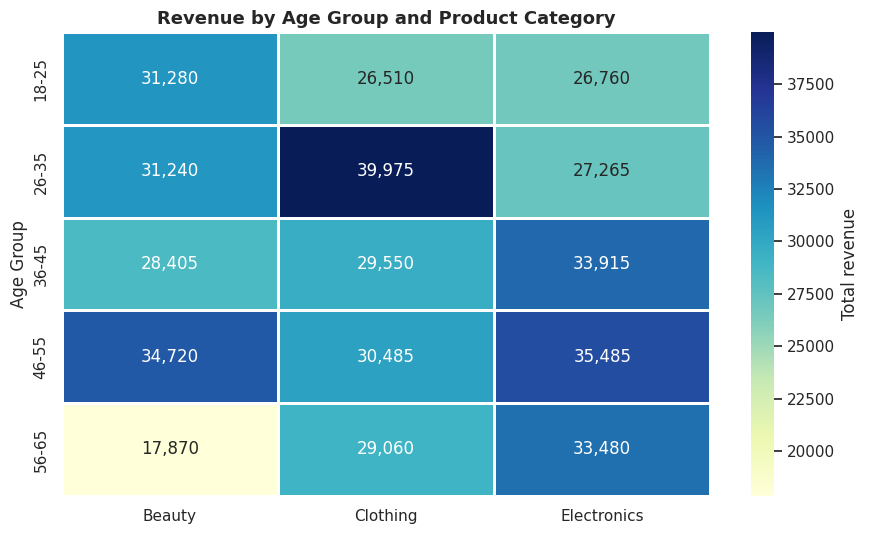

In [16]:
age_cat = df.pivot_table(index='Age Group', columns='Product Category',
                         values='Total Amount', aggfunc='sum', observed=True)

plt.figure(figsize=(9, 5.5))
sns.heatmap(age_cat, annot=True, fmt=',.0f', cmap='YlGnBu', linewidths=1, linecolor='white',
            cbar_kws={'label': 'Total revenue'})
plt.title('Revenue by Age Group and Product Category')
plt.ylabel('Age Group')
plt.xlabel('')
plt.tight_layout()
plt.show()

**Observations**

- **Beauty is strongest with the youngest customers** (18-25: 31,280) and the 46-55 group (34,720), but it **collapses for the 56-65 group (17,870)**, which is the lowest cell in the whole table.
- **Clothing peaks with the 26-35 group** (39,975), the single biggest age-and-category combination in the dataset.
- **Electronics grows with age**, from 26,760 among 18-25 year olds to 35,485 for 46-55 and 33,480 for 56-65. Older customers are electronics buyers.
- Put together, each age group has its own favourite category. A single store-wide promotion is therefore a weaker idea than category offers aimed at specific age groups.

### 7.3 Is there a weekly pattern?

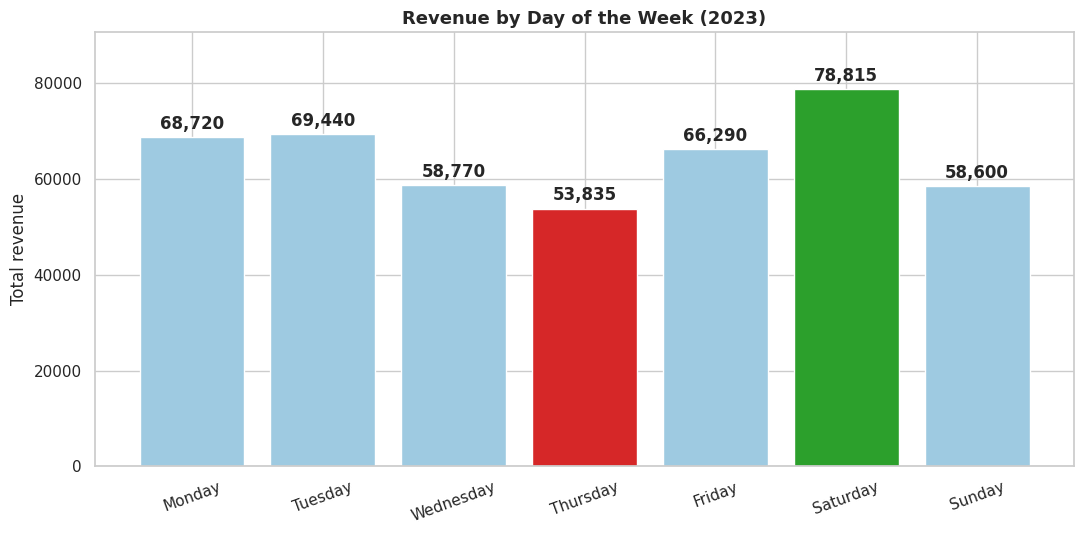

,Revenue,Transactions
Day of Week,,
Monday,68720,144
Tuesday,69440,161
Wednesday,58770,139
Thursday,53835,123
Friday,66290,143
Saturday,78815,150
Sunday,58600,138


In [17]:
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow = df23.groupby('Day of Week').agg(Revenue=('Total Amount', 'sum'),
                                      Transactions=('Transaction ID', 'count')).reindex(order)

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = ['#d62728' if d == dow['Revenue'].idxmin() else '#2ca02c' if d == dow['Revenue'].idxmax() else '#9ecae1' for d in dow.index]
bars = ax.bar(dow.index, dow['Revenue'], color=colors)
ax.bar_label(bars, fmt='{:,.0f}', padding=3, fontweight='bold')
ax.set_title('Revenue by Day of the Week (2023)')
ax.set_ylabel('Total revenue')
ax.set_ylim(0, dow['Revenue'].max() * 1.15)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

dow

**Observations**

- **Saturday is the best day** by a clear margin (78,815), and it also has the highest average order value (about 525).
- **Thursday is the weakest day** (53,835) with the fewest transactions (123).
- Mid-week (Wednesday) and Sunday are also on the slower side, while Monday and Tuesday are surprisingly solid.
- The weekly pattern is milder than the monthly one, so I would treat it as a secondary lever and not as the main driver.

## 8. Summary of Key Findings

| # | Finding | Evidence |
|---|---|---|
| 1 | The data is clean and complete | No nulls, no duplicates, Total Amount always matches Quantity x Price |
| 2 | Sales are seasonal | May is the peak (53,150); September is the low (23,620); Q3 is the weakest quarter, Q4 the strongest |
| 3 | A small premium segment drives the business | 39.6% of orders (price 300 / 500) produce 88.4% of revenue |
| 4 | Customers do not buy fewer units when prices rise | Average quantity is about 2.5 at every price point (correlation 0.02) |
| 5 | Gender and age shape *what* people buy, not *how much* | Equal average order values for men and women; women prefer Clothing, men prefer Electronics |
| 6 | Younger customers spend more per order | Average order value drops from about 500 (18-25) to about 412 (56-65) |
| 7 | Beauty is the weakest category, especially with 56-65 year olds | 143,515 overall; just 17,870 in the 56-65 group |
| 8 | Saturday is the strongest trading day, Thursday the weakest | 78,815 vs 53,835 |

## 9. Conclusion and Business Recommendations

This analysis of 1,000 retail transactions shows a healthy, well-balanced business with an even customer mix and three categories of almost equal size. Underneath that balance, though, there are some sharp patterns: revenue is concentrated in premium purchases, sales dip noticeably in the third quarter, and each customer group has its own taste. These patterns lead to the following recommendations.

### Recommendation 1: Build the strategy around the premium range (price 300 and 500)
Premium items are about 40% of orders but 88% of revenue, and customers keep buying the same number of units even at higher prices. The business should give premium products the best shelf and website placement, bundle low-priced items (25 to 50) with premium ones to lift order value, and test a few more products in the 300-500 range. Even a small increase in premium orders will move revenue more than any amount of growth in budget sales.

### Recommendation 2: Fix the September slump with a planned campaign
September revenue (23,620) is less than half of May (53,150) and drags Q3 down by about 22%. The data shows a strong rebound in October (+97%), so demand is there, it is just delayed. I recommend launching a back-to-season or early-festive offer in late August and September, and moving some of the October promotions earlier to catch that demand sooner. Stock and staffing should also be planned around the real peaks (May, October and December) so the business is not caught short.

### Recommendation 3: Target customers by age and category, not with one-size-fits-all offers
- **Women aged 26-35** are the top-spending group and love Clothing, so run clothing launches and loyalty offers aimed at them.
- **Customers aged 18-25** have the highest average order value (about 500) but are the smallest group, so student or first-job offers are a good way to grow this high-value segment.
- **Customers aged 56-65** spend the least on Beauty. Either create a Beauty offer designed for this age group (simple routines, gift sets) or shift their marketing towards Electronics, where they spend well.
- **Men** lean towards Electronics, so electronics cross-sell campaigns (accessories, upgrades) should target them first.

### Recommendation 4: Lift the weakest day and the weakest category
Thursday is the slowest day (53,835), while Saturday leads (78,815). Midweek flash sales or "Thursday deals" can bring more footfall on the quiet day, and Saturday should be fully staffed and stocked. Beauty is the weakest category on every measure, but it is only about 8% behind the leaders. Pairing Beauty with Clothing in combo offers is a low-cost way to close that gap.

### Recommendation 5: Start collecting richer data
This dataset has no product names and every customer appears only once, so I could not study repeat buying, loyalty or individual products. Capturing product names/SKUs, repeat-customer IDs and the sales channel would make the next analysis far more useful, especially for retention and product-level decisions.

### Limitations
- The data covers a single year, so I cannot say whether the seasonal pattern repeats every year.
- Each customer appears only once, so no repeat-purchase or lifetime-value analysis was possible.
- Products are represented only by category and price point.
- Correlations show relationships, not causes. The ideas above should be tested (for example with a small pilot promotion) before a full rollout.

---
*End of analysis. Prepared by Saurabh Shukla (saurabhshuklant@gmail.com).*